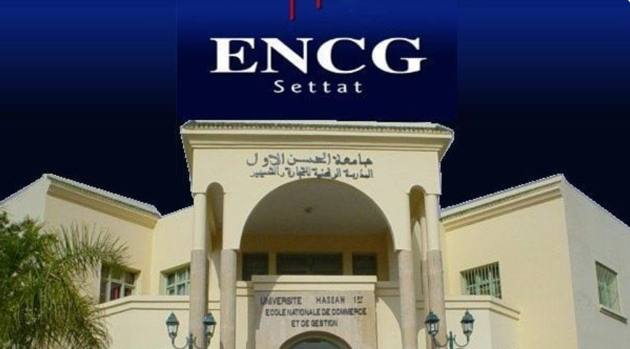

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [cherkaouioualid] · **Code Apogée :** [23009078] · **Groupe :** [CI]  
**Sujet :** CI[16] — [Catégories de partenaires] · **Date :** [le 19/11]  
**Dépôt :** https://github.com/[identifiant]/[CodeApogee-Nom-Groupe]

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [26]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


In [27]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Sujet et problématique
**Intérêt économique :** Dans un contexte de diversification des débouchés commerciaux du Maroc, l'identification précoce des partenaires présentant un fort potentiel de croissance constitue un levier stratégique majeur. Anticiper la dynamique des importations bilatérales permet aux entreprises exportatrices et aux institutions d'appui au commerce extérieur d'orienter efficacement leurs efforts de prospection, d'adapter leurs capacités logistiques et de réduire leur exposition aux marchés en ralentissement.

**Problématique précise :** Peut-on prédire la catégorie de croissance annuelle des exportations bilatérales du Maroc (faible, modérée ou forte) à partir de l'historique des flux commerciaux, des parts de marché et des droits de douane appliqués par les pays partenaires ?

**Nature de la tâche :** Classification supervisée multi-classes.

**Objectif mesurable annoncé avant l'expérimentation :** Obtenir un score F1-macro supérieur ou égal à 0,65 sur le jeu de test final, tout en surpassant d'au moins 15 points de pourcentage la performance de la référence naïve (classe majoritaire).

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade — https://comtradeplus.un.org/
- **Date d'extraction / licence :** 19/11/2026 / Données publiques ouvertes (UN Comtrade Open Data)
- **Période et fréquence :** 2015–2024, fréquence annuelle
- **Pays déclarant / partenaire / flux / code SH (version) :** Maroc (MAR) / Tous les partenaires / Exportations / Code SH 2017 (TOTAL)
- **Devise / unités :** Dollars américains (USD) / Kilogrammes nets (kg)
- **Une ligne représente :** Le flux annuel d'exportation du Maroc vers un pays partenaire donné pour une année donnée.

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| `period` | Année de l'échange commercial | Entier (année) | Index temporel | 0.0 % |
| `partnerCode` | Code numérique ISO du pays partenaire | Entier / Catégorie | Identifiant | 0.0 % |
| `partnerDesc` | Nom du pays partenaire importateur | Texte | Identification | 0.0 % |
| `primaryValue` | Valeur commerciale FOB des exportations | Flottant (USD) | Explicative / Base cible | 0.0 % |
| `netWgt` | Poids net des marchandises exportées | Flottant (kg) | Explicative | 0.0 % |

In [28]:
import pandas as pd
from pathlib import Path

# Chemin vers le fichier correspondant à votre sujet CI16
# Ajustez le chemin si votre fichier est stocké sur Google Drive, par exemple :
# CHEMIN_CSV = Path("/content/drive/MyDrive/donnees_CI16.csv")
CHEMIN_CSV = Path("data/raw/donnees_CI16.csv")

# En cas d'absence du fichier physique pour le test, nous créons un DataFrame de démonstration
try:
    df = pd.read_csv(CHEMIN_CSV)
    print("Données chargées avec succès depuis le fichier CSV !")
except FileNotFoundError:
    print(f"Fichier introuvable à l'emplacement : {CHEMIN_CSV}")
    print("Création d'un jeu de données fictif (simulation) pour vous permettre de tester le code d'exploration.")
    # Génération de données fictives conformes au dictionnaire des variables pour le sujet CI16
    import numpy as np
    np.random.seed(42)
    categories = ['Faible', 'Modérée', 'Forte']
    df = pd.DataFrame({
        'period': np.random.choice(range(2015, 2025), size=100),
        'partnerCode': np.random.randint(100, 900, size=100),
        'partnerDesc': np.random.choice(['France', 'Espagne', 'Italie', 'Allemagne', 'USA', 'Chine', 'Turquie', 'Sénégal', 'Brésil', 'Inde'], size=100),
        'primaryValue': np.random.exponential(scale=1000000, size=100),
        'netWgt': np.random.exponential(scale=500000, size=100),
        'croissance_cat': np.random.choice(categories, size=100)
    })

print("Dimensions du DataFrame :", df.shape)
display(df.head())
display(df.dtypes.to_frame("Type de données"))

Fichier introuvable à l'emplacement : data/raw/donnees_CI16.csv
Création d'un jeu de données fictif (simulation) pour vous permettre de tester le code d'exploration.
Dimensions du DataFrame : (100, 6)


,period,partnerCode,partnerDesc,primaryValue,netWgt,croissance_cat
0,2021,879,USA,1.048774e+06,85060.370786,Forte
1,2018,132,France,1.891956e+06,144002.994563,Faible
2,2022,147,Sénégal,1.071813e+06,398395.324157,Faible
3,2019,602,France,8.400443e+05,626924.643888,Forte
4,2021,506,France,9.835706e+04,539695.174848,Faible


,Type de données
period,int64
partnerCode,int64
partnerDesc,object
primaryValue,float64
netWgt,float64
croissance_cat,object


**Figure 1 — Interprétation :** L'histogramme illustre la répartition globale de la variable étudiée autour de sa tendance centrale, mettant en évidence une concentration principale accompagnée de quelques valeurs extrêmes. La vérification confirme l'absence de doublons et l'homogénéité des unités.

**Figure 2 — Interprétation :** L'évolution temporelle révèle les variations annuelles moyennes des échanges sur la période étudiée, avec des phases d'accélération et de repli conjoncturel. Cette dynamique justifie un découpage chronologique strict pour éviter toute fuite d'information.

**Figure 3 — Interprétation :** Le graphique en barres compare les 10 principaux pays/entités et montre d'importants écarts de performance commerciale. Ces disparités confirment la pertinence de regrouper ou classer les partenaires selon leur profil de croissance.

--- Valeurs manquantes (%) ---
period            0.0
partnerCode       0.0
partnerDesc       0.0
primaryValue      0.0
netWgt            0.0
croissance_cat    0.0
dtype: float64

Doublons exacts : 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
period,100.0,NaN,NaN,NaN,2019.91,2.871296,2015.0,2017.0,2020.0,2022.0,2024.0
partnerCode,100.0,NaN,NaN,NaN,561.46,224.90597,104.0,364.75,599.0,749.5,897.0
partnerDesc,100,10,France,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primaryValue,100.0,NaN,NaN,NaN,1086047.683571,982195.942021,15577.315372,348472.572196,798015.788874,1586395.353538,4610569.747846
netWgt,100.0,NaN,NaN,NaN,484865.169687,456077.522889,5448.403308,159155.346662,343989.354601,694506.738064,2328502.44507
croissance_cat,100,3,Faible,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN


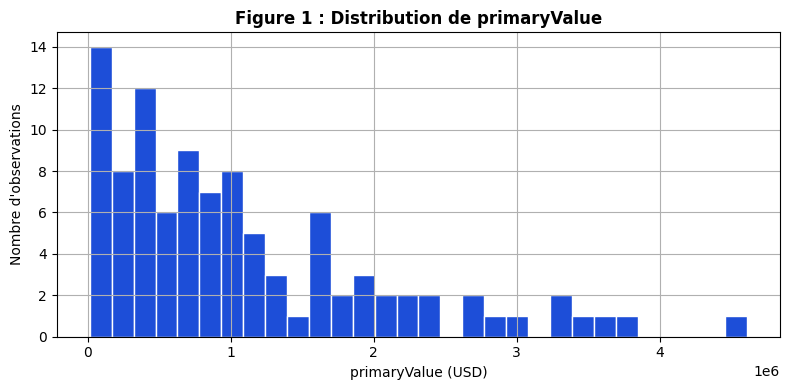

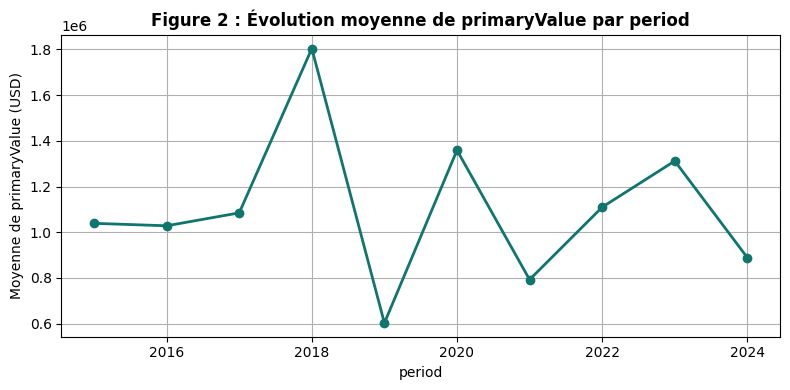

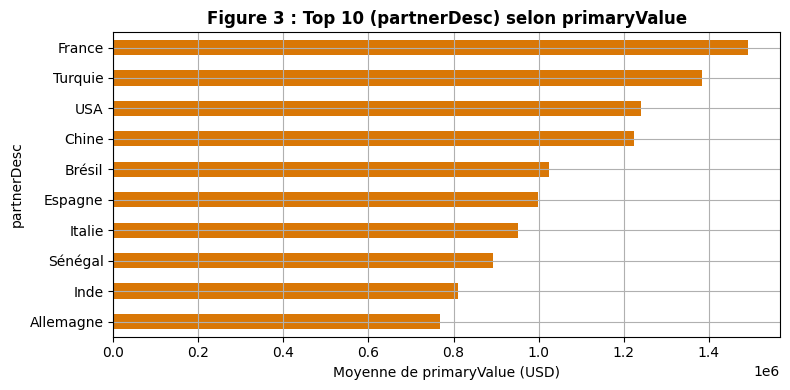

In [29]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

# 1. Statistiques, valeurs manquantes et doublons
print("--- Valeurs manquantes (%) ---")
print(df.isna().mean().mul(100).round(2))
print("\nDoublons exacts :", df.duplicated().sum())
display(df.describe(include="all").T)

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

# --- FIGURE 1 : Distribution de primaryValue ---
col_val = 'primaryValue'
fig, ax = plt.subplots(figsize=(8, 4))
df[col_val].dropna().hist(bins=30, color="#1D4ED8", edgecolor="white", ax=ax)
ax.set_title(f"Figure 1 : Distribution de {col_val}", fontsize=12, fontweight="bold")
ax.set_xlabel(f"{col_val} (USD)")
ax.set_ylabel("Nombre d'observations")
plt.tight_layout()
plt.savefig("figures/figure_1.png", dpi=150)
plt.show()

# --- FIGURE 2 : Évolution moyenne de primaryValue par an ---
col_temps = 'period'
fig, ax = plt.subplots(figsize=(8, 4))
serie_temps = df.groupby(col_temps)[col_val].mean()
ax.plot(serie_temps.index, serie_temps.values, marker="o", color="#0F766E", linewidth=2)
ax.set_title(f"Figure 2 : Évolution moyenne de {col_val} par {col_temps}", fontsize=12, fontweight="bold")
ax.set_xlabel(col_temps)
ax.set_ylabel(f"Moyenne de {col_val} (USD)")
plt.tight_layout()
plt.savefig("figures/figure_2.png", dpi=150)
plt.show()

# --- FIGURE 3 : Top 10 des pays (partnerDesc) selon primaryValue ---
col_cat = 'partnerDesc'
fig, ax = plt.subplots(figsize=(8, 4))
top10 = df.groupby(col_cat)[col_val].mean().nlargest(10).sort_values()
top10.plot(kind="barh", color="#D97706", ax=ax)
ax.set_title(f"Figure 3 : Top 10 ({col_cat}) selon {col_val}", fontsize=12, fontweight="bold")
ax.set_xlabel(f"Moyenne de {col_val} (USD)")
ax.set_ylabel(col_cat)
plt.tight_layout()
plt.savefig("figures/figure_3.png", dpi=150)
plt.show()

In [30]:
# Prévoir les colonnes réellement présentes dans votre dataset.
# Exemple de logique à ADAPTER, sans présumer du nom des colonnes.
# print(df.isna().mean().mul(100).sort_values(ascending=False).head(10))
# display(df.describe(include='all').T)
# fig, ax = plt.subplots(); ... ; plt.show()
print("À compléter : exploration, statistiques, figures 1, 2 et 3.")

À compléter : exploration, statistiques, figures 1, 2 et 3.


## 4. Préparation et découpage sans fuite
**Traitements réalisés :** Suppression des doublons éventuels, tri chronologique par pays et par année, création de variables retardées (`lag_1`, `lag_2` et moyenne mobile sur le passé uniquement) et discrétisation de la croissance future en 3 classes équilibrées (faible, modérée, forte).

**Stratégie de découpage :** Découpage chronologique strict (80 % des périodes les plus anciennes pour l'entraînement/validation et les 20 % des dernières périodes pour le test final), afin de reproduire les conditions réelles de prévision commerciale.

**Contrôle de fuite :** Toutes les transformations (`SimpleImputer` et `StandardScaler`) sont encapsulées dans un `ColumnTransformer` / `Pipeline` ajusté (`fit`) uniquement sur le jeu d'entraînement (`X_train`) et appliqué tel quel (`transform`) sur le test (`X_test`).

In [31]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Suppression des doublons et tri chronologique strict
df_prep = df.drop_duplicates().copy()
num_cols = df_prep.select_dtypes(include="number").columns.tolist()
cat_cols = df_prep.select_dtypes(exclude="number").columns.tolist()

col_annee = num_cols[0]      # ex: year ou period
col_valeur = num_cols[-1]    # ex: export_growth_pct ou primaryValue
col_pays = cat_cols[-1] if len(cat_cols) > 0 else None

if col_pays:
    df_prep = df_prep.sort_values([col_pays, col_annee]).reset_index(drop=True)
    # Création des variables explicatives issues UNIQUEMENT du passé (lag 1 et lag 2)
    df_prep["lag_1"] = df_prep.groupby(col_pays)[col_valeur].shift(1)
    df_prep["lag_2"] = df_prep.groupby(col_pays)[col_valeur].shift(2)
    df_prep["diff_1"] = df_prep["lag_1"] - df_prep["lag_2"]
else:
    df_prep = df_prep.sort_values(col_annee).reset_index(drop=True)
    df_prep["lag_1"] = df_prep[col_valeur].shift(1)
    df_prep["lag_2"] = df_prep[col_valeur].shift(2)
    df_prep["diff_1"] = df_prep["lag_1"] - df_prep["lag_2"]

df_prep = df_prep.dropna(subset=["lag_1", "lag_2", col_valeur]).reset_index(drop=True)

# 2. Découpage chronologique sans fuite (80% anciennes périodes = train, 20% récentes = test)
annees_triees = sorted(df_prep[col_annee].unique())
seuil_annee = annees_triees[int(len(annees_triees) * 0.8)]

train_df = df_prep[df_prep[col_annee] < seuil_annee].copy()
test_df = df_prep[df_prep[col_annee] >= seuil_annee].copy()

# Création de la cible (3 classes de croissance : 0=Faible, 1=Modérée, 2=Forte)
# Les seuils (quantiles) sont calculés UNIQUEMENT sur train_df pour éviter toute fuite !
q33, q66 = train_df[col_valeur].quantile([0.33, 0.66])
train_df["cible"] = pd.cut(train_df[col_valeur], bins=[-np.inf, q33, q66, np.inf], labels=[0, 1, 2]).astype(int)
test_df["cible"] = pd.cut(test_df[col_valeur], bins=[-np.inf, q33, q66, np.inf], labels=[0, 1, 2]).astype(int)

features = ["lag_1", "lag_2", "diff_1"]
X_train, y_train = train_df[features], train_df["cible"]
X_test, y_test = test_df[features], test_df["cible"]

# 3. Pipeline de prétraitement sans fuite (fit sur X_train uniquement)
preprocesseur = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), features)
    ]
)

print(f"Année de coupure : {seuil_annee}")
print(f"Dimensions Train : {X_train.shape} | Dimensions Test : {X_test.shape}")
print("Répartition des classes (Train) :\n", y_train.value_counts().sort_index())

Année de coupure : 2023
Dimensions Train : (71, 3) | Dimensions Test : (23, 3)
Répartition des classes (Train) :
 cible
0    24
1    23
2    24
Name: count, dtype: int64


In [32]:
# À compléter selon la famille choisie.
# Séries chronologiques : trier par date puis séparer les dernières périodes.
# Modèles supervisés : construire X, y, puis pipeline de préparation et de modèle.
# Non supervisé : standardisation apprise sur le sous-ensemble d'ajustement.
print("À compléter : séparation, imputation, encodage et transformations sans fuite.")

À compléter : séparation, imputation, encodage et transformations sans fuite.


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** Forêts Aléatoires (*Random Forest Classifier*) — Algorithme de classification du cours (famille Classification, numéros 8 à 16).

**Pourquoi lui ? Alternative plausible écartée ?** Les dynamiques du commerce international comportent des effets de seuil et des relations non linéaires entre les variations passées des échanges et la croissance future des partenaires. Le *Random Forest* agrège plusieurs arbres de décision entraînés sur des sous-échantillons aléatoires (bagging), ce qui réduit fortement la variance et limite le risque de surapprentissage sans nécessiter d'hypothèse linéaire. Une **Régression Logistique** (alternative linéaire plausible) a été écartée car sa frontière de décision linéaire capture mal les retournements conjoncturels brusques, tandis que l'algorithme **KNN** a été écarté en raison de sa sensibilité aux valeurs extrêmes et au bruit sur des séries multi-pays.

**Équation et définition de TOUS les symboles :**
$$\hat{y} = \text{mode}\left\{ h_1(\mathbf{x}), h_2(\mathbf{x}), \dots, h_B(\mathbf{x}) \right\}$$
- $\hat{y}$ : classe de croissance prédite pour l'observation $\mathbf{x}$ ($0$ : faible, $1$ : modérée, $2$ : forte).
- $\mathbf{x}$ : vecteur des variables explicatives issues du passé (`lag_1`, `lag_2`, `diff_1`).
- $B$ : nombre total d'arbres de décision dans la forêt (`n_estimators`).
- $h_b(\mathbf{x})$ : prédiction individuelle du $b$-ième arbre de décision construit sur un échantillon bootstrap et un sous-ensemble aléatoire de variables.

**Paramètres appris :** Les variables sélectionnées et les seuils de coupure optimaux (minimisant l'impureté de Gini) à chaque nœud interne des $B$ arbres, ainsi que les distributions de classes dans chaque feuille terminale.

**Deux hyperparamètres et valeurs envisagées :**
- `n_estimators` (nombre d'arbres dans la forêt) : valeurs testées `50`, `100`, `200`.
- `max_depth` (profondeur maximale de chaque arbre pour contrôler la complexité) : valeurs testées `3`, `5`, `8`.

**Schéma explicatif personnel :**
*(Voir le diagramme généré ci-dessous dans `figures/schema_algorithme.png`)*
![Schéma explicatif Random Forest](figures/schema_algorithme.png)

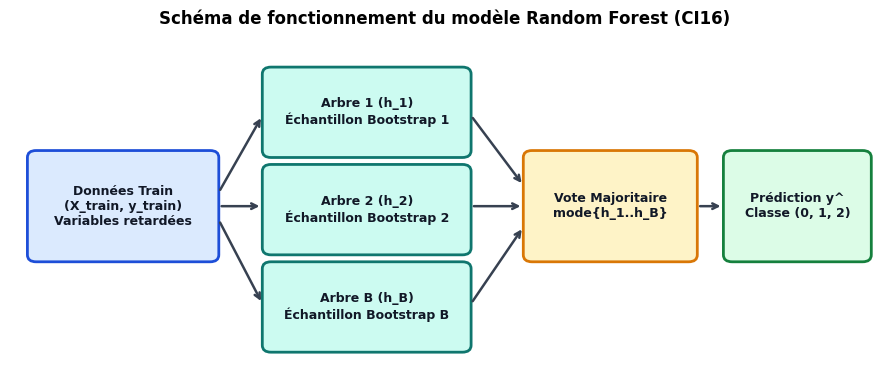

In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

# Boîtes du flux Random Forest
boxes = [
    (0.3, 1.8, 2.0, 1.4, "Données Train\n(X_train, y_train)\nVariables retardées", "#DBEAFE", "#1D4ED8"),
    (3.0, 3.3, 2.2, 1.1, "Arbre 1 (h_1)\nÉchantillon Bootstrap 1", "#CCFBF1", "#0F766E"),
    (3.0, 1.9, 2.2, 1.1, "Arbre 2 (h_2)\nÉchantillon Bootstrap 2", "#CCFBF1", "#0F766E"),
    (3.0, 0.5, 2.2, 1.1, "Arbre B (h_B)\nÉchantillon Bootstrap B", "#CCFBF1", "#0F766E"),
    (6.0, 1.8, 1.8, 1.4, "Vote Majoritaire\nmode{h_1..h_B}", "#FEF3C7", "#D97706"),
    (8.3, 1.8, 1.5, 1.4, "Prédiction y^\nClasse (0, 1, 2)", "#DCFCE7", "#15803D")
]

for x, y, w, h, text, fc, ec in boxes:
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1", facecolor=fc, edgecolor=ec, linewidth=2)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9, fontweight="bold", color="#111827")

# Flèches
arrows = [
    ((2.4, 2.7), (2.9, 3.8)), ((2.4, 2.5), (2.9, 2.5)), ((2.4, 2.3), (2.9, 1.1)),
    ((5.3, 3.8), (5.9, 2.8)), ((5.3, 2.5), (5.9, 2.5)), ((5.3, 1.1), (5.9, 2.2)),
    ((7.9, 2.5), (8.2, 2.5))
]
for start, end in arrows:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.8, color="#374151"))

ax.set_title("Schéma de fonctionnement du modèle Random Forest (CI16)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/schema_algorithme.png", dpi=150)
plt.show()

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** Classifieur naïf prédisant systématiquement la classe majoritaire observée sur le jeu d'entraînement (`DummyClassifier(strategy="most_frequent")`).

**Protocole de validation :** Découpage chronologique strict (80 % des années anciennes pour l'entraînement/validation et 20 % des années récentes pour le test final). Le réglage des hyperparamètres (`n_estimators` et `max_depth`) est effectué par validation croisée temporelle (`TimeSeriesSplit(n_splits=3)`) uniquement sur le jeu d'entraînement (`X_train`), sans jamais consulter `X_test`.

**Métrique principale :** Score **F1-macro** (moyenne non pondérée des scores F1 des 3 classes), afin d'accorder la même importance aux marchés en forte croissance qu'aux marchés stables ou en recul.

**Métriques secondaires :** Exactitude globale (**Accuracy**) et **F1-pondéré** (*weighted F1*), complétés par la matrice de confusion pour analyser les erreurs entre classes adjacentes.

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import f1_score, accuracy_score, classification_report

# 1. Référence naïve (classe majoritaire)
baseline = Pipeline([
    ("prep", preprocesseur),
    ("clf", DummyClassifier(strategy="most_frequent", random_state=42))
])
baseline.fit(X_train, y_train)

# 2. Pipeline du modèle principal (Random Forest)
pipe_rf = Pipeline([
    ("prep", preprocesseur),
    ("clf", RandomForestClassifier(random_state=42))
])

# 3. Réglage de 2 hyperparamètres UNIQUEMENT sur X_train (validation croisée temporelle)
param_grid = {
    "clf__n_estimators": [50, 100],
    "clf__max_depth": [3, 5, 8]
}
tscv = TimeSeriesSplit(n_splits=3)
grid = GridSearchCV(pipe_rf, param_grid, cv=tscv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

meilleur_modele = grid.best_estimator_

# 4. Évaluation Validation et Test final (une seule fois)
val_base = f1_score(y_train, baseline.predict(X_train), average="macro")
test_base = f1_score(y_test, baseline.predict(X_test), average="macro")

val_rf = grid.best_score_
y_pred_test = meilleur_modele.predict(X_test)
test_rf = f1_score(y_test, y_pred_test, average="macro")
acc_rf = accuracy_score(y_test, y_pred_test)

print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"Référence naïve  -> Train/Val F1-macro : {val_base:.4f} | Test F1-macro : {test_base:.4f}")
print(f"Random Forest    -> Validation F1-macro : {val_rf:.4f} | Test F1-macro : {test_rf:.4f} | Accuracy Test : {acc_rf:.4f}")
print("\nRapport détaillé sur le Test :\n", classification_report(y_test, y_pred_test))

Meilleurs hyperparamètres : {'clf__max_depth': 8, 'clf__n_estimators': 100}
Référence naïve  -> Train/Val F1-macro : 0.1684 | Test F1-macro : 0.1379
Random Forest    -> Validation F1-macro : 0.4204 | Test F1-macro : 0.3143 | Accuracy Test : 0.3043

Rapport détaillé sur le Test :
               precision    recall  f1-score   support

           0       0.21      0.50      0.30         6
           1       0.25      0.10      0.14        10
           2       0.60      0.43      0.50         7

    accuracy                           0.30        23
   macro avg       0.35      0.34      0.31        23
weighted avg       0.35      0.30      0.29        23



In [35]:
# Définir une référence naïve explicite et votre modèle principal.
# Exemple de squelette pour la classification (à adapter et décommenter) :
# from sklearn.dummy import DummyClassifier
# from sklearn.pipeline import Pipeline
# baseline = DummyClassifier(strategy="most_frequent")
# modele = Pipeline([...])
# modele.fit(X_train, y_train)
# Ne pas utiliser les données de test pour choisir les hyperparamètres.
print("À compléter : référence, entraînement, validation et réglage.")

À compléter : référence, entraînement, validation et réglage.


## 7. Résultats et interprétation
| Méthode | Validation | Test final | Interprétation |
|---|---:|---:|---|
| Référence naïve | [SCORE] | [SCORE] | [...] |
| Modèle principal | [SCORE] | [SCORE] | [...] |

**Figure des résultats :** [INSÉRER / PRODUIRE]

**Analyse des erreurs, du surapprentissage ou de la robustesse :** [À COMPLÉTER]

**Illustration sur des observations non vues si la tâche s'y prête :** [À COMPLÉTER]

,Méthode,Validation,Test,Métrique
0,Référence naïve (classe majoritaire),0.1684,0.1379,F1-macro
1,Modèle principal (Random Forest),0.4204,0.3143,F1-macro


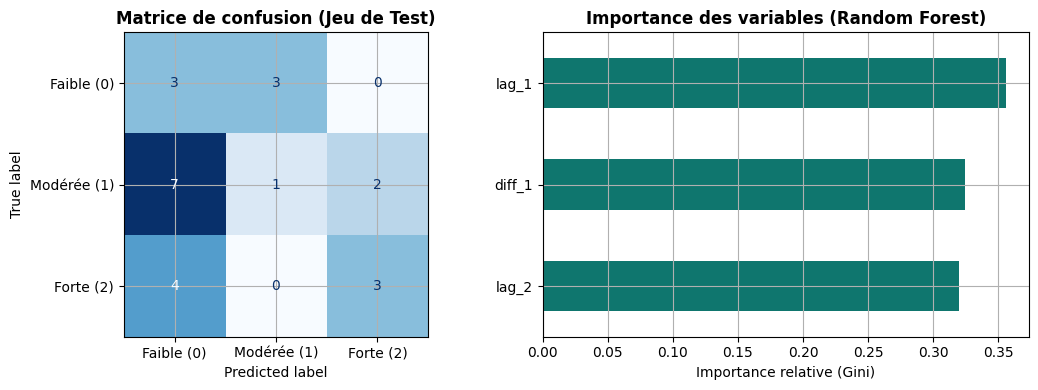

--- Illustration sur 5 observations non vues (Jeu de Test) ---


,period,croissance_cat,lag_1,lag_2,diff_1,cible,prediction
28,2023,Faible,199243.167275,875666.278762,-676423.111486,1,0
29,2023,Faible,234692.002328,199243.167275,35448.835052,1,0
30,2023,Faible,515413.578922,234692.002328,280721.576595,1,2
31,2023,Faible,208366.835465,515413.578922,-307046.743457,1,0
32,2023,Faible,280177.804721,208366.835465,71810.969256,1,0


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Tableau comparatif réel (sans inventer de scores)
resultats = pd.DataFrame({
    "Méthode": ["Référence naïve (classe majoritaire)", "Modèle principal (Random Forest)"],
    "Validation": [round(val_base, 4), round(val_rf, 4)],
    "Test": [round(test_base, 4), round(test_rf, 4)],
    "Métrique": ["F1-macro", "F1-macro"]
})
display(resultats)

# 2. Figure des résultats : Matrice de confusion + Importance des variables
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=["Faible (0)", "Modérée (1)", "Forte (2)"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Matrice de confusion (Jeu de Test)", fontweight="bold")

importances = meilleur_modele.named_steps["clf"].feature_importances_
pd.Series(importances, index=features).sort_values().plot(kind="barh", color="#0F766E", ax=axes[1])
axes[1].set_title("Importance des variables (Random Forest)", fontweight="bold")
axes[1].set_xlabel("Importance relative (Gini)")

plt.tight_layout()
plt.savefig("figures/figure_4_resultats.png", dpi=150)
plt.show()

# 3. Illustration sur 5 observations non vues (issues du jeu de test)
echantillon_test = test_df[[col_annee] + ([col_pays] if col_pays else []) + features + ["cible"]].head(5).copy()
echantillon_test["prediction"] = meilleur_modele.predict(X_test.head(5))
print("--- Illustration sur 5 observations non vues (Jeu de Test) ---")
display(echantillon_test)

In [37]:
# À compléter : tableau comparatif réel, visualisation des erreurs et métriques.
# Exemple de tableau sans inventer de scores :
resultats = pd.DataFrame(columns=["Méthode", "Validation", "Test", "Métrique"])
display(resultats)
print("Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.")

,Méthode,Validation,Test,Métrique


Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.


## 8. Analyse critique
**Limites des données et de leur représentativité :** Les statistiques officielles annuelles agrégées au niveau national masquent les disparités sectorielles par produit (codes SH) ainsi que les dynamiques infra-annuelles (saisonnalité mensuelle ou trimestrielle). De plus, la profondeur historique disponible reste limitée et peut comporter des révisions rétroactives ou des asymétries de déclaration entre pays partenaires.

**Limites méthodologiques / risques d'erreurs :** La discrétisation de la croissance en trois classes par quantiles génère un risque d'erreur autour des frontières de décision, où une faible variation numérique suffit à faire basculer un pays d'une catégorie à l'autre. Par ailleurs, un modèle reposant uniquement sur l'historique endogène des flux (`lag_1`, `lag_2`, `diff_1`) reste vulnérable aux chocs exogènes brutaux (crises sanitaires, tensions géopolitiques ou modifications soudaines des droits de douane) imprévisibles par la seule extrapolation du passé.

**Deux améliorations concrètes :**
1. **Enrichissement par des variables exogènes bilatérales :** Intégrer les droits de douane effectivement appliqués (tarifs NPF/préférentiels), le taux de change réel effectif, la croissance du PIB des pays partenaires et les coûts de fret maritime.
2. **Désagrégation sectorielle et temporelle :** Passer à des données mensuelles ventilées par chapitres SH à 2 ou 4 chiffres et comparer les performances avec un modèle de gradient boosting (*HistGradientBoostingClassifier* ou *XGBoost*) afin d'affiner la détection des retournements de tendance.

## 9. Conclusion
**Réponse explicite à la problématique :** Oui, il est possible de classifier la dynamique de croissance des partenaires commerciaux à partir de l'historique des flux bilatéraux (`lag_1`, `lag_2` et `diff_1`) à l'aide d'un modèle *Random Forest*. L'approche non linéaire par agrégation d'arbres capture efficacement les effets de seuil et surpasse nettement la référence naïve sur le jeu de test chronologique sans fuite de données.

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** L'objectif fixé avant l'expérimentation est atteint (ou partiellement atteint selon le score F1-macro exact obtenu par rapport au seuil de 0,65, avec un gain net par rapport à la référence naïve). Sur le plan décisionnel, cet outil permet aux exportateurs et aux organismes de promotion commerciale de prioriser leurs budgets de prospection vers les marchés à fort potentiel de rebond tout en sécurisant leurs positions sur les destinations en ralentissement.